# Do unique players pay off?
### Initial analysis (COS 424 project, Milestone 2)

This notebook loads the raw data, cleans it, explores it, and runs a first version of the detection
model. The implementation lives in `src/` and the notebook only calls it:

| module | what it does |
|---|---|
| `src/prepare.py` | loads the three raw files and builds the cleaned table of prospects |
| `src/summaries.py` | descriptive tables |
| `src/plots.py` | charts |
| `src/detect.py` | first version of the model that scores how unusual each prospect is (Mahalanobis distance) |

To reproduce: `pip install -r requirements.txt`, then run every cell from the top. The raw files are in `data/raw/`.

In [1]:
import pandas as pd

from src import detect, plots, prepare, summaries

plots.use_style()
pd.set_option("display.max_columns", 40, "display.max_colwidth", 80)

## 1. The data

Three files from the open [nflverse](https://github.com/nflverse/nflverse-data) project, downloaded in October 2026.

In [2]:
raw = prepare.load_raw()
summaries.raw_overview(raw)

,one row is,rows,columns,years
file,,,,
combine.csv,a prospect at one combine,8968,18,2000-2026
draft_picks.csv,a draft pick,12927,36,1980-2026
players.csv,a player on an NFL roster,24844,39,all years


The combine file is the core of the project. Each row is one prospect:

| column | meaning |
|---|---|
| `season` | year of the combine |
| `pos` | position listed at the combine |
| `ht`, `wt` | height (feet-inches) and weight (lb) |
| `forty` | 40-yard dash, in seconds |
| `bench` | bench press, repetitions at 225 lb |
| `vertical`, `broad_jump` | jumps, in inches |
| `cone`, `shuttle` | 3-cone drill and 20-yard shuttle, in seconds |
| `draft_year`, `draft_round`, `draft_ovr` | when and where the prospect was drafted; empty if he was not |

From the draft file we take each pick's team and `w_av`, the player's career "weighted Approximate Value":
Pro-Football-Reference's single number for how much a player contributed over his career.
The players file is used only to look up the position a prospect went on to play in the NFL.

In [3]:
raw["combine"].head()

,season,draft_year,draft_team,draft_round,draft_ovr,pfr_id,cfb_id,player_name,pos,school,ht,wt,forty,bench,vertical,broad_jump,cone,shuttle
0,2000,2000.0,New York Jets,1.0,13.0,AbraJo00,NaN,John Abraham,OLB,South Carolina,6-4,252.0,4.55,NaN,NaN,NaN,NaN,NaN
1,2000,2000.0,Seattle Seahawks,1.0,19.0,AlexSh00,shaun-alexander-1,Shaun Alexander,RB,Alabama,6-0,218.0,4.58,NaN,NaN,NaN,NaN,NaN
2,2000,2000.0,Kansas City Chiefs,6.0,188.0,AlfoDa20,NaN,Darnell Alford,OT,Boston Col.,6-4,334.0,5.56,23.0,25.0,94.0,8.48,4.98
3,2000,NaN,NaN,NaN,NaN,NaN,NaN,Kyle Allamon,TE,Texas Tech,6-2,253.0,4.97,NaN,29.0,104.0,7.29,4.49
4,2000,2000.0,Carolina Panthers,1.0,23.0,AndeRa21,NaN,Rashard Anderson,CB,Jackson State,6-2,206.0,4.55,NaN,34.0,123.0,7.18,4.15


## 2. Preprocessing

`prepare.build_prospects()` runs every cleaning step and keeps a log of what each one changed.

In [4]:
prospects, cleaning_log = prepare.build_prospects()
cleaning_log

,step,rows_changed,rows_remaining,effect
0,Raw combine file,0,8968,starting point
1,Link newest class to its draft picks by name,218,8968,draft slot filled in
2,Clear picks from a different year than the combine,8,8968,treated as undrafted
3,Two same-class namesakes claim one pick,3,8965,row dropped
4,Drafted but no career value on record,440,8965,career value set to 0
5,"Specialists and fullbacks (K, P, LS, FB)",431,8534,row dropped
6,"No height, weight or 40-yard dash",830,7704,left out of the sample
7,Weight impossible for the listed position,9,7695,left out of the sample


What each step does, in the order of the log:

1. **Link the newest class to its draft picks.** The combine file has no draft columns yet for the 2026 class,
   so those prospects are matched to the 2026 draft by name (ignoring suffixes such as "Jr.").
2. **Clear picks from a different year.** A prospect is drafted in the year of his combine. A few rows point at a
   pick from another year: two players with the same name were given one player ID, and the pick belongs to the
   other one. These rows keep their measurements and count as undrafted.
3. **Two namesakes, one pick.** In three classes, two prospects with the same name claim the same pick. The pick
   stays with the one whose position matches the drafted position. The other row is dropped, because his real
   draft outcome cannot be recovered from the file.
4. **Players who never played.** A drafted player with no career value on record never appeared in an NFL game,
   so his career value is set to 0.
5. **Position groups.** The combine's position labels are mapped to eleven groups: QB, RB, WR, TE, OT, IOL
   (guards and centers), DT, EDGE, LB, CB and S. Kickers, punters, long snappers and fullbacks are dropped.
   Four labels are ambiguous (OLB, OL, DL, DB); they are resolved with the position the player held in the NFL,
   or by body size when he never played.
6. **The sample.** The analysis uses prospects who have a height, a weight and a 40-yard dash on record.
   Rows whose weight is impossible for the listed position are treated as mislabelled and left out.

The cleaned table keeps every position player; the column `in_sample` marks the rows the analysis uses.

The rows behind step 2, as they appear in the raw file:

In [5]:
combine = raw["combine"]
other_year = combine["draft_year"].notna() & (combine["draft_year"] != combine["season"])
combine.loc[other_year, ["season", "player_name", "pos", "school", "draft_year", "draft_ovr", "pfr_id"]]

,season,player_name,pos,school,draft_year,draft_ovr,pfr_id
159,2000,Eric Johnson,S,Yale,2001.0,224.0,JohnEr00
313,2000,Jack Williams,S,Azusa Pacific,2008.0,119.0,WillJa96
360,2001,Chris Brown,OT,Georgia Tech,2003.0,93.0,BrowCh03
943,2002,Jeff Webb,P,Vanderbilt,2006.0,190.0,WebbJe00
1605,2004,Travis Wilson,FB,Kansas State,2006.0,78.0,WilsTr00
3311,2010,Chris Carter,WR,California-Davis,2011.0,162.0,CartCh00
4200,2012,Phillip Thomas,S,Syracuse,2013.0,119.0,ThomPh00
4304,2013,Mike Edwards,CB,Hawaii,2019.0,99.0,EdwaMi01


And the rows left out in step 6 for an impossible size (most come from the 2021 class, which had no combine):

In [6]:
prospects.loc[prospects["size_error"], ["season", "player_name", "pos", "grp", "ht", "wt", "forty"]]

,season,player_name,pos,grp,ht,wt,forty
629,2002,Ben Miller,C,IOL,74.0,263.0,4.92
1355,2004,Josh Buhl,OLB,LB,71.0,204.0,4.73
6456,2020,Nick Coe,LB,LB,77.0,280.0,4.89
6591,2021,Carson Williams,OL,IOL,76.0,254.0,4.79
6611,2021,DAnte Smith,LB,LB,77.0,305.0,5.29
6723,2021,Jarell White,LB,LB,68.0,202.0,4.58
6725,2021,Jarrett Patterson,OL,IOL,66.0,195.0,4.52
6746,2021,John Brunner,OL,IOL,74.0,194.0,NaN
6837,2021,Noah Hannon,OL,IOL,72.0,238.0,5.15
6940,2021,Tyler Coyle,LB,LB,73.0,209.0,4.38


## 3. Descriptive statistics

The sample by position group. `position_players` counts everyone in the cleaned table; the other columns
describe the rows in the sample.

In [7]:
summaries.show(summaries.sample_by_position(prospects), percent=["share_drafted"])

,position_players,in_sample,drafted,share_drafted,median_height_in,median_weight_lb,median_forty_s
QB,477,413,239,58%,75.0,222.0,4.81
RB,779,716,424,59%,70.0,213.0,4.55
WR,1245,1158,710,61%,73.0,201.0,4.50
TE,512,452,299,66%,76.0,252.0,4.75
OT,677,609,441,72%,78.0,313.0,5.22
IOL,802,722,434,60%,76.0,309.0,5.25
DT,677,604,431,71%,75.0,306.0,5.08
EDGE,924,826,604,73%,75.0,262.0,4.78
LB,823,718,483,67%,73.0,237.0,4.68
CB,948,876,622,71%,71.0,192.0,4.49


Each measurement across the whole sample. Height, weight and the 40 are complete by construction; the other
five drills are often skipped.

In [8]:
summaries.show(summaries.measurement_summary(prospects), percent=["missing_share"])

,recorded,missing_share,mean,std,min,median,max
Height (in),7695,0%,73.85,2.67,65.00,74.00,82.00
Weight (lb),7695,0%,243.51,46.27,149.00,233.00,375.00
40-yard dash (s),7695,0%,4.76,0.31,4.21,4.67,6.05
Bench press (reps),4956,36%,20.73,6.37,2.00,21.00,49.00
Vertical jump (in),6407,17%,33.08,4.24,17.50,33.50,46.50
Broad jump (in),6320,18%,115.13,9.48,74.00,116.00,147.00
3-cone drill (s),4855,37%,7.29,0.42,6.28,7.19,9.12
20-yard shuttle (s),4997,35%,4.40,0.27,3.73,4.36,5.56


## 4. Exploring the data

### 4.1 How many prospects are there, and how complete are they?

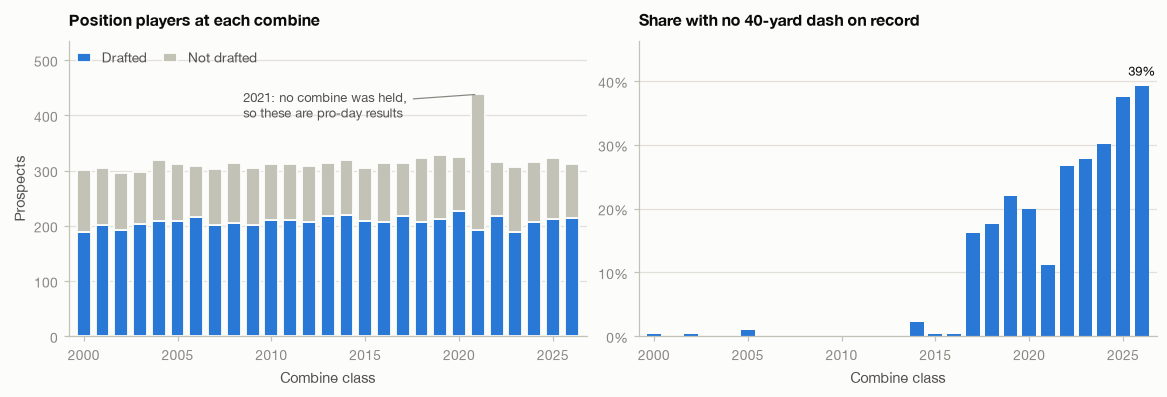

In [9]:
per_class = summaries.prospects_per_class(prospects)
missing_forty = summaries.missing_forty_by_class(prospects)
plots.coverage_by_class(per_class, missing_forty)

- Each class has about 300 to 330 position players, and about two thirds of them are drafted.
- 2021 is the exception. No combine was held that year, so the file holds pro-day results for a larger and
  weaker pool: more prospects, and a much smaller share drafted.
- Until 2016 almost every prospect has a 40 time. From 2017 a growing share has none, and those prospects
  fall out of our sample.

The table below checks whether the missing 40 times since 2017 are concentrated among early picks.

In [10]:
summaries.show(summaries.missing_forty_by_round(prospects), percent=["share_no_forty"])

,prospects,no_forty,share_no_forty
drafted in (2017-2025 classes),,,
Round 1,274,72,26%
Round 2,280,71,25%
Round 3,330,66,20%
Round 4,287,60,21%
Round 5,287,64,22%
Round 6,238,57,24%
Round 7,186,35,19%
Undrafted,1104,254,23%


They are a little more common in rounds 1 and 2, but every round and the undrafted group are affected.

### 4.2 Which drills do prospects complete?

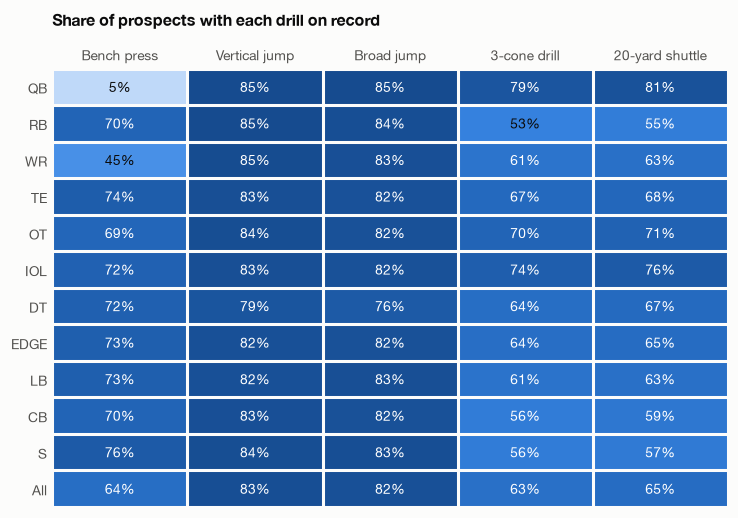

In [11]:
plots.drill_coverage(summaries.drill_coverage(prospects))

In [12]:
summaries.show(summaries.drill_coverage_by_era(prospects), percent=prepare.DRILLS[1:])

,bench,vertical,broad_jump,cone,shuttle
combine classes,,,,,
2000-2010,65%,78%,77%,66%,66%
2011-2016,75%,83%,82%,70%,72%
2017-2021,79%,93%,91%,72%,75%
2022-2026,23%,89%,86%,31%,36%


- The jumps are recorded for more than 80% of the sample; bench, 3-cone and shuttle for about two thirds.
- Quarterbacks almost never bench, and fewer than half of receivers do.
- Coverage changes over time: since 2022 far fewer prospects have a bench, 3-cone or shuttle result.

So the analysis cannot require all six drills. It has to work with prospects who skipped some.

### 4.3 Size and speed depend on position

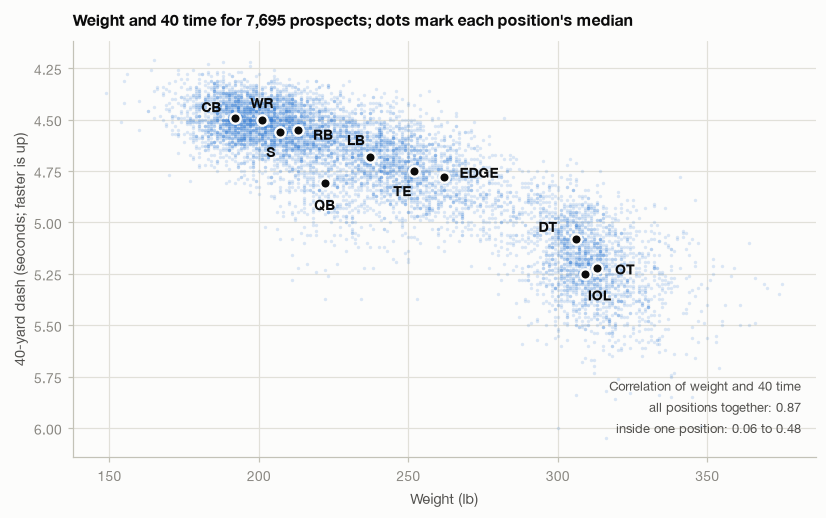

In [13]:
correlation = summaries.size_speed_correlation(prospects)
plots.size_and_speed(prospects, correlation)

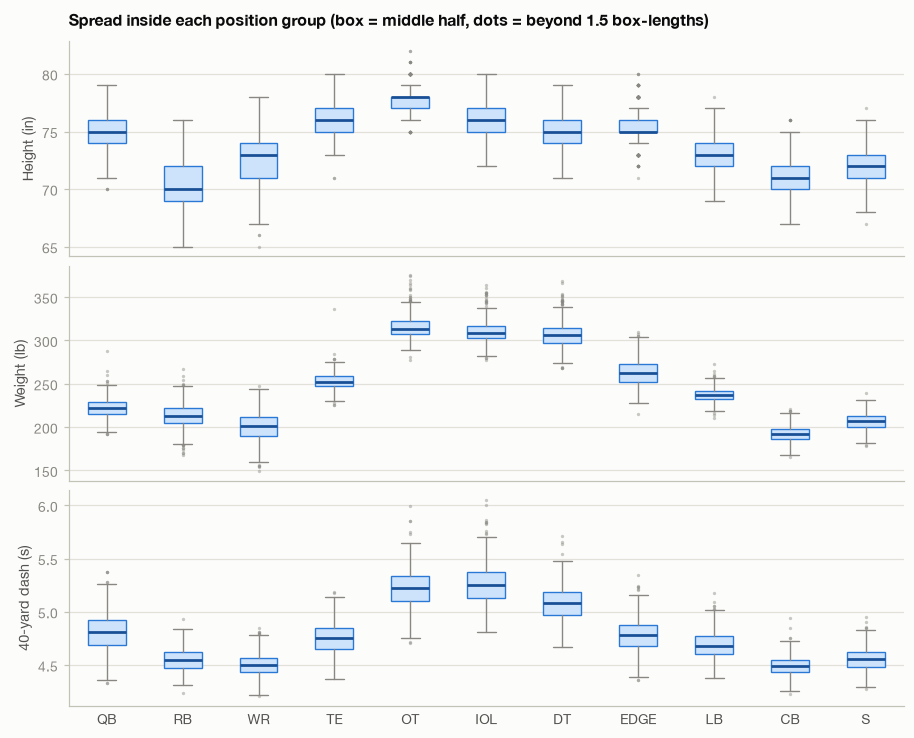

In [14]:
plots.spread_by_position(prospects)

- Across all positions, weight and 40 time are tightly linked: a time that is slow for a receiver is fast for
  a defensive tackle.
- Inside one position the link is much weaker, and every position has its own range of heights, weights and times.

So "unusual" only means something relative to a prospect's own position, and speed has to be read against size.

### 4.4 Prospects test better over time

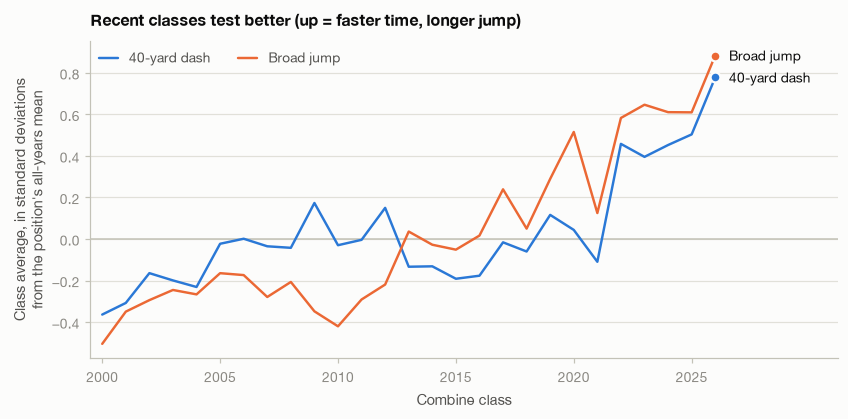

In [15]:
trend = summaries.testing_by_class(prospects)
plots.testing_by_class(trend)

Each line compares a class with the all-years average for the same position, in standard deviations.
Recent classes run faster and jump farther than earlier ones. Part of this may be selection, since 4.1 showed
that fewer recent prospects run the 40 at all. Either way, a recent prospect should be compared with his own
era, otherwise he looks unusual only because of when he was tested.

## 5. Draft outcomes and career value

In [16]:
picks = prepare.clean_draft_picks(raw["draft_picks"])
summaries.show(summaries.career_value_by_round(picks), percent=["never_played", "zero_career_value"], decimals=1)

,picks,mean,median,p90,max,never_played,zero_career_value
Round 1,508,44.7,41.0,86.0,169.0,0%,0%
Round 2,506,28.8,24.0,60.0,167.0,1%,3%
Round 3,542,18.9,11.0,46.0,140.0,3%,8%
Round 4,574,14.8,8.0,41.0,114.0,6%,18%
Round 5,558,10.0,3.0,33.0,97.0,13%,27%
Round 6,596,7.5,2.0,22.0,184.0,20%,36%
Round 7,729,6.0,1.0,19.0,78.0,25%,46%


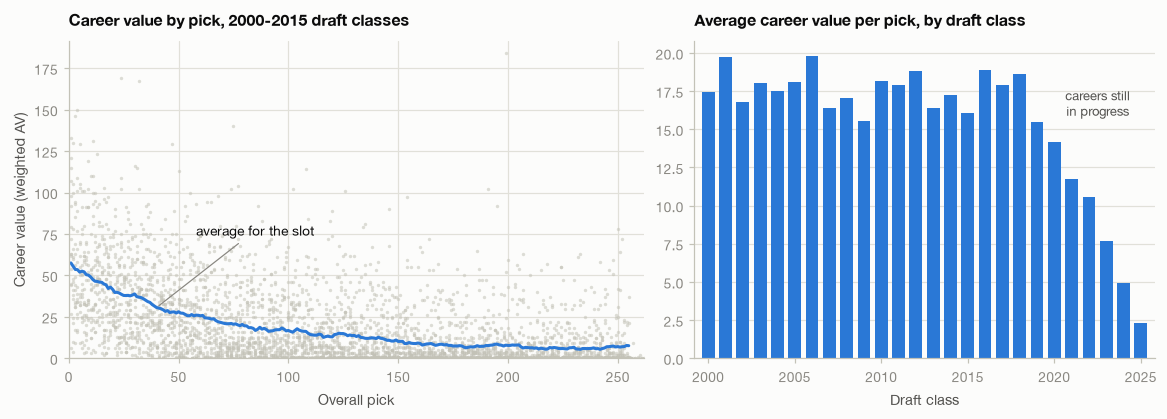

In [17]:
plots.career_value(picks, summaries.career_value_by_pick(picks), summaries.career_value_by_class(picks))

- Career value falls steeply with draft position, and it is skewed: in every round the mean is above the median.
- A quarter of seventh-round picks never play a game, and nearly half finish with a career value of zero.
- Career value keeps growing while a player is active, so recent classes have lower totals.

So a career can only be judged against what the same draft slot usually returns, and recent classes need care.

## 6. A first look at the question: do teams pay for speed?

Before any model, a simple cut: rank each prospect's 40 time inside his position group and split into fifths.

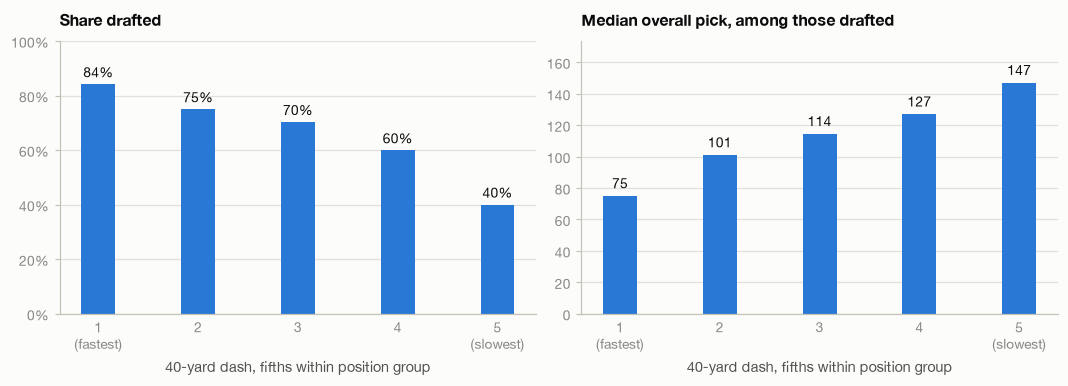

In [18]:
by_speed = summaries.drafted_by_speed(prospects)
plots.drafted_by_speed(by_speed)

In [19]:
summaries.show(by_speed, percent=["share_drafted"], decimals=1)

,prospects,share_drafted,median_pick_if_drafted
40-time fifth within position,,,
1 (fastest),1497,84%,75.0
2,1500,75%,101.0
3,1502,70%,114.5
4,1500,60%,127.0
5 (slowest),1507,40%,147.0


The fastest fifth at a position is drafted about twice as often as the slowest fifth, and much earlier.
This uses one measurement only; the project's detection step will use the whole profile.

## 7. The numbers in one place

In [20]:
summaries.headline_numbers(prospects, picks)

,value
what,
Combine classes,2000-2026 (27 classes)
Position players in the cleaned table,"8,534"
Prospects in the analysis sample,"7,695"
of whom drafted,"5,084 (66%)"
Drill results missing in the sample,24%
"Average drills completed, of 6",4.6
No 40-yard dash on record: 2000-2016 classes,0.3%
No 40-yard dash on record: 2017-2021 classes,17%
No 40-yard dash on record: 2022-2026 classes,32%


What the exploration means for the next steps:

- **Detecting unusual prospects** has to happen inside each position group, with drills read against body size
  and against the prospect's own era (4.3, 4.4).
- **Skipped drills** are common and have become more common, so the method must handle missing drills (4.2).
- **Grading careers** has to be relative to the draft slot, and the most recent classes cannot be graded yet (5).
- **Coverage** is a limitation: since 2017 a growing share of prospects has no 40 time and is outside the sample (4.1).

## 8. First model: which prospects have unusual size and speed?

This is a first version of the detection step. It uses the three measurements every prospect in the sample
has (height, weight and the 40-yard dash), so no skipped drill has to be filled in yet.

For each position group, `detect.score_prospects()`:

1. builds three features: height, weight and speed for size (the 40 time compared with what the prospect's
   height and weight predict). Each is measured against prospects at the same position from classes within
   two years of his own;
2. scores every prospect with the **Mahalanobis distance**: how far he is from the centre of his position,
   allowing for how the three features move together;
3. flags the top 5% of each position as unusual.

Flagged prospects are then labelled by direction: fast for their size, slow for their size, or neither
(an unusual build). Nothing in this step sees draft position or career outcomes.

In [21]:
scored = detect.score_prospects(prospects)
summaries.unusual_by_position(scored)

,prospects,"Unusual, fast for size",Unusual build,"Unusual, slow for size",Typical
QB,413,8,5,8,392
RB,716,4,17,15,680
WR,1158,18,15,25,1100
TE,452,6,9,8,429
OT,609,8,10,13,578
IOL,722,8,17,12,685
DT,604,9,10,12,573
EDGE,826,12,15,15,784
LB,718,8,9,19,682
CB,876,13,13,18,832


### Why one method, and why Mahalanobis distance?

We started with three unsupervised detectors (Isolation Forest, Local Outlier Factor and Mahalanobis distance)
and keep one. Three checks, in order: how similar their rankings are, how each one compares with the average
of all three, and how much each one's flags move when its own setting is changed.

In [22]:
summaries.detector_agreement(scored).round(2)

,isolation_forest,local_outlier_factor,mahalanobis
isolation_forest,1.00,0.92,0.98
local_outlier_factor,0.92,1.00,0.93
mahalanobis,0.98,0.93,1.00


In [23]:
summaries.show(summaries.method_comparison(scored), percent=["share_of_average_flags"], decimals=3)

,correlation_with_average,flags,also_flagged_by_average,share_of_average_flags
isolation_forest,0.986,390,318,82%
local_outlier_factor,0.967,390,331,85%
mahalanobis,0.989,390,340,87%


In [24]:
detect.settings_sensitivity(prospects)

,what_was_changed,flags,flags_that_change
detector,,,
isolation_forest,a different random seed,390,38
local_outlier_factor,20 neighbours instead of 35,390,53
mahalanobis,nothing to change: re-run as is,390,0


In [25]:
summaries.flag_overlap(scored)

,prospects,flagged_by_our_method
in the top 5% of,,
all three detectors,241,241
two detectors,151,112
one detector,145,37
none,7158,0


- The three detectors rank prospects almost identically, so little is lost by using one of them.
- They still do not agree on every flag: fewer than half of the prospects flagged by any detector are flagged
  by all three. A single, stable rule is easier to defend than an average of three moving parts.
- Mahalanobis distance is the closest of the three to the average of all three.
- It is the only one with no setting to choose and no randomness, so it gives the same flags on every run.
  Isolation Forest changes some of its flags with the random seed, and Local Outlier Factor with the number of
  neighbours.
- It is also the simplest to explain: a distance from the centre of the position, in standard deviations.

### Who is flagged?

Three position groups as examples, then the highest-scoring prospects who are fast for their size.

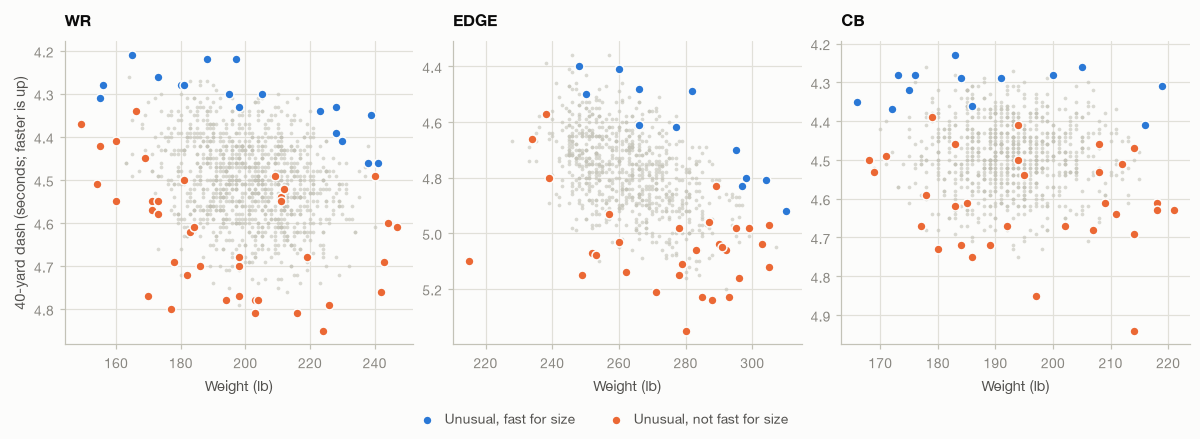

In [26]:
plots.unusual_examples(scored)

In [27]:
summaries.most_unusual(scored, kind="Unusual, fast for size").round(2)

,player_name,season,grp,ht,wt,forty,height_z,weight_z,speed_z,score,kind,draft_ovr
0,Mike Williams,2002,OT,78.0,375.0,5.30,0.00,5.64,1.21,1.00,"Unusual, fast for size",4.0
1,Jordan Davis,2022,DT,78.0,341.0,4.78,2.02,2.85,3.07,1.00,"Unusual, fast for size",13.0
2,J.J. Nelson,2015,WR,70.0,156.0,4.28,-1.01,-2.95,1.44,1.00,"Unusual, fast for size",159.0
3,Dont'a Hightower,2012,LB,74.0,265.0,4.62,0.67,3.37,2.06,1.00,"Unusual, fast for size",25.0
4,Rock Cartwright,2002,RB,68.0,237.0,4.47,-2.02,1.64,1.82,1.00,"Unusual, fast for size",257.0
5,Emmanuel Forbes,2023,CB,73.0,166.0,4.35,0.67,-2.81,1.24,1.00,"Unusual, fast for size",16.0
6,Jeoffrey Pagan,2014,EDGE,75.0,310.0,4.92,0.00,3.20,1.65,1.00,"Unusual, fast for size",177.0
7,Trenton Brown,2015,IOL,80.0,355.0,5.21,2.70,4.34,1.68,1.00,"Unusual, fast for size",244.0
8,Demarcus Van Dyke,2011,CB,73.0,176.0,4.28,1.35,-1.80,2.22,1.00,"Unusual, fast for size",81.0
9,Mekhi Becton,2020,OT,79.0,364.0,5.10,1.35,5.01,1.91,1.00,"Unusual, fast for size",11.0


Flagged prospects sit at the edges of each position's cloud. The fast-for-size list includes players known for
rare size and speed, such as Jordan Davis, Patrick Peterson and Mekhi Becton.

### Does the era comparison matter?

The same model, run again with every prospect compared against all classes instead of his own era.

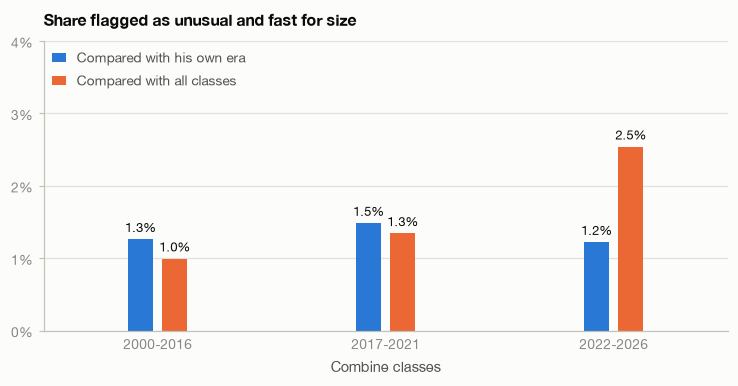

In [28]:
scored_all_classes = detect.score_prospects(prospects, era_window=None)
plots.fast_flags_by_era(summaries.fast_flags_by_era(scored, scored_all_classes))

In [29]:
summaries.flag_changes(scored, scored_all_classes)

,prospects
flagged as unusual,
under both comparisons,313
only when compared with his own era,77
only when compared with all classes,77


Compared with all classes at once, prospects from 2022-2026 are flagged as unusual and fast about two and a half
times as often as prospects from 2000-2016. Compared with their own era, the rate is similar in every period.
The choice changes which prospects are flagged, so it is one of the decisions the project has to justify.

### A first look at draft outcomes

For each kind of prospect, classes through 2025.

In [30]:
summaries.show(summaries.draft_outcomes_by_kind(scored),
               percent=["share_drafted", "round_1_share_of_drafted"], decimals=1)

,prospects,share_drafted,median_pick_if_drafted,round_1_share_of_drafted
kind,,,,
"Unusual, fast for size",100,92%,61.5,38%
Unusual build,128,64%,118.5,12%
"Unusual, slow for size",159,23%,191.5,3%
Typical,7119,66%,108.0,15%


Prospects flagged as unusual and fast for their size are drafted far more often, and much earlier, than typical
prospects. Those flagged as slow for their size are rarely drafted. This shows what teams pay, not what they get
back: comparing careers with the draft slot is the next step.

### What this first version leaves out

- the other five drills, which need a way to handle skipped drills and a decision on how to weigh them;
- checks on the choices made here: the 5% cut-off, the two-year era window and the cut-off for "fast for size";
- grading careers against the draft slot.